# RQ3 — How does train–test homology separation reshape functional generalization?

## Scientific question

**How does progressively increasing sequence separation between training and test proteins alter functional prediction, and which biological tasks and model families remain reliable under increasingly remote generalization?**

Homology-separation threshold:

\[
S \in \{90,70,50,30\}
\]

where lower `S` corresponds to stricter train–test separation.

Unlike `R`, which changes the available evidence before splitting, `S` changes **how that fixed R-level universe is partitioned into homology-separated train and test groups**.

### Main objectives

1. reconstruct the complete `S90 → S70 → S50 → S30` response at every fixed `R`;
2. quantify all six possible S contrasts;
3. identify whether remote-generalization loss is monotonic, threshold-like, flat, or non-monotonic;
4. determine which tasks, representations, and learners are most homology-sensitive;
5. quantify performance retained relative to `S90`;
6. determine whether representation quality changes the *shape* of remote-generalization degradation;
7. inspect how stricter S changes split topology, test prevalence, and effective cluster granularity;
8. assess whether the S effect is conditioned by R without yet performing the formal `R×S` interaction analysis.

> **Scope rule:** native S conditions use different cluster-based test partitions and are therefore not automatically paired. Common-test sensitivity across S is reserved for the dedicated common-test RQ.

## Interpretation contract

- `S` controls whole-cluster train/test separation.
- At fixed `R`, the biological universe is the same, but the cluster topology and resulting train/test membership can change with `S`.
- Native S contrasts therefore estimate **generalization across alternative homology-separated test populations**, not paired per-protein effects.
- MCC is the primary supervised metric.
- Binary AP is complemented with normalized AP skill.
- Test prevalence and positive support are tracked explicitly because whole-cluster assignment can shift class composition.
- Cluster counts at different S thresholds are treated as **split-topology / granularity descriptors**, not literal surviving clusters.
- Any apparent `R×S` interaction is carried forward to the dedicated interaction RQ.

In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 300)
pd.set_option("display.width", 220)
pd.set_option("display.max_rows", 300)

R_LEVELS = [90, 70, 50, 30]
S_LEVELS = [90, 70, 50, 30]

TASK_PATHS = {
    "global_easy": "global_easy",
    "global_hard": "global_hard",
    "global_mixed": "global_mixed",
    "subtype_endolysin": "subtype_binary/endolysin",
    "subtype_depolymerase": "subtype_binary/depolymerase",
    "subtype_val": "subtype_binary/virion_associated_lytic_enzyme",
    "multiclass_clean": "multiclass_clean",
}

BINARY_TASKS = [
    "global_easy",
    "global_hard",
    "global_mixed",
    "subtype_endolysin",
    "subtype_depolymerase",
    "subtype_val",
]

def find_project_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (
            (candidate / "results/analysis_supervised/stage12a").is_dir()
            and (candidate / "results/analysis_supervised/stage12b").is_dir()
        ):
            return candidate
    raise FileNotFoundError(
        "Could not locate project root containing stage12a and stage12b outputs."
    )

ROOT = find_project_root()
STAGE12A = ROOT / "results/analysis_supervised/stage12a"
STAGE12B = ROOT / "results/analysis_supervised/stage12b"
PREDICTIVE_ROOT = ROOT / "data/predictive_universe"
CACHE_DIR = ROOT / "results/analysis_supervised/notebook_cache"
CACHE_DIR.mkdir(parents=True, exist_ok=True)

print("ROOT:", ROOT)

ROOT: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass


In [2]:
master = pd.read_csv(
    STAGE12A / "supervised_master_results.tsv",
    sep="\t",
    low_memory=False,
)

# Stage12B naming is expected from the finalized analysis builder.
candidate_s_files = [
    STAGE12B / "rs_split_deltas_fixed_R.tsv",
    STAGE12B / "rs_homology_deltas_fixed_R.tsv",
    STAGE12B / "rs_separation_deltas_fixed_R.tsv",
    STAGE12B / "s_deltas_fixed_R.tsv",
]

s_delta_path = next((p for p in candidate_s_files if p.is_file()), None)

if s_delta_path is None:
    available = sorted(p.name for p in STAGE12B.glob("*.tsv"))
    raise FileNotFoundError(
        "Could not find the fixed-R S-delta table. Available Stage12B TSVs:\n"
        + "\n".join(available)
    )

s_deltas = pd.read_csv(
    s_delta_path,
    sep="\t",
    low_memory=False,
)

print("S-delta table:", s_delta_path.name)
print("Experiment families:", len(master))
print("Tasks:", sorted(master["task"].unique()))
print("Representations:", sorted(master["representation"].unique()))
print("Algorithms:", sorted(master["algorithm"].unique()))

coverage = (
    master.groupby(["task", "representation", "algorithm"])
    .size()
    .rename("n_RxS")
    .reset_index()
)

display(coverage["n_RxS"].value_counts().sort_index().to_frame("n_groups"))
assert coverage["n_RxS"].eq(16).all(), "Incomplete R×S surface detected."

S-delta table: rs_split_deltas_fixed_R.tsv
Experiment families: 2240
Tasks: ['global_easy', 'global_hard', 'global_mixed', 'multiclass_clean', 'subtype_depolymerase', 'subtype_endolysin', 'subtype_val']
Representations: ['esm2_t30_150m', 'esm2_t6_8m', 'onehot_1024', 'roxy_48']
Algorithms: ['KNN', 'LR', 'MLP', 'RF', 'XGB']


,n_groups
n_RxS,
16,140


## 1. Prevalence-normalized AP skill

In [3]:
def detect_prevalence(df):
    candidates = [
        "test_prevalence",
        "prevalence",
        "positive_prevalence",
        "class_prevalence",
    ]
    for c in candidates:
        if c in df.columns:
            return pd.to_numeric(df[c], errors="coerce"), c

    if {"n_positive", "n_test"} <= set(df.columns):
        return (
            pd.to_numeric(df["n_positive"], errors="coerce")
            / pd.to_numeric(df["n_test"], errors="coerce")
        ), "derived_from_n_positive_n_test"

    if {"tp", "fn", "tn", "fp"} <= set(df.columns):
        pos = pd.to_numeric(df["tp"], errors="coerce") + pd.to_numeric(df["fn"], errors="coerce")
        n = pos + pd.to_numeric(df["tn"], errors="coerce") + pd.to_numeric(df["fp"], errors="coerce")
        return pos / n, "derived_from_confusion_counts"

    return pd.Series(np.nan, index=df.index), None

prevalence, prevalence_source = detect_prevalence(master)
master["prevalence_for_ap"] = prevalence

if "ap" in master.columns:
    denom = 1.0 - master["prevalence_for_ap"]
    master["ap_skill"] = np.where(
        denom > 0,
        (master["ap"] - master["prevalence_for_ap"]) / denom,
        np.nan,
    )

print("Prevalence source:", prevalence_source)
print("AP skill available:", "ap_skill" in master.columns)

Prevalence source: prevalence
AP skill available: True


## 2. Global homology-separation trajectories

,task,S,mcc_median,mcc_mean,mcc_min,mcc_max
0,global_easy,30,0.701754,0.667684,0.111129,0.948037
1,global_easy,50,0.710370,0.684592,0.116259,0.953930
2,global_easy,70,0.741163,0.695063,0.123060,0.963380
3,global_easy,90,0.741735,0.701435,0.132234,0.962580
4,global_hard,30,0.893263,0.868916,0.684547,0.954039
5,global_hard,50,0.896593,0.862934,0.668715,0.953800
6,global_hard,70,0.895904,0.867314,0.666141,0.960467
7,global_hard,90,0.898515,0.878066,0.695514,0.964477
8,global_mixed,30,0.688660,0.661964,0.098878,0.948935
9,global_mixed,50,0.710862,0.677568,0.126920,0.952116


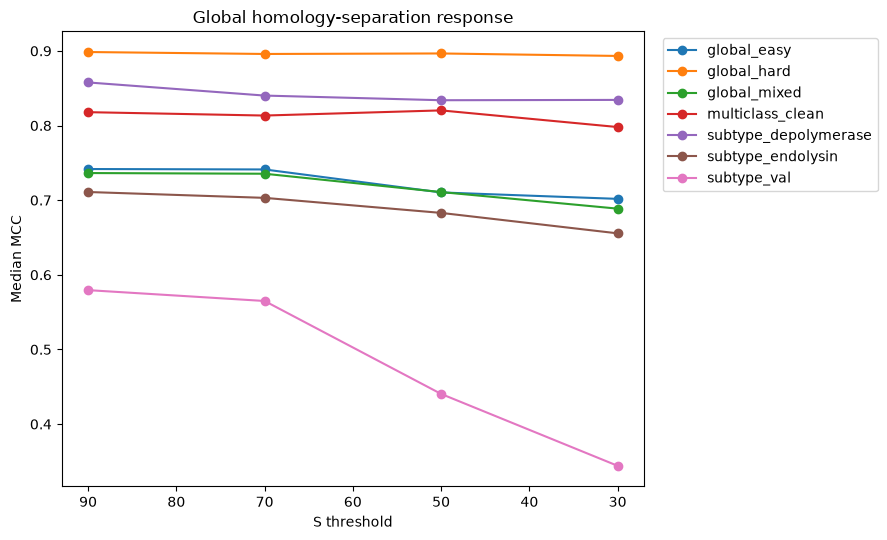

In [4]:
overview = (
    master.groupby(["task", "S"], as_index=False)
    .agg(
        mcc_median=("mcc", "median"),
        mcc_mean=("mcc", "mean"),
        mcc_min=("mcc", "min"),
        mcc_max=("mcc", "max"),
    )
)

display(overview)

fig, ax = plt.subplots(figsize=(9, 5.5))
for task, g in overview.groupby("task"):
    g = g.set_index("S").reindex(S_LEVELS)
    ax.plot(
        S_LEVELS,
        g["mcc_median"],
        marker="o",
        label=task,
    )

ax.set_xlabel("S threshold")
ax.set_ylabel("Median MCC")
ax.set_title("Global homology-separation response")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 3. Complete S curves at fixed R

For each `task × representation × algorithm`, four curves are available:

\[
M(S\mid R=90),\;
M(S\mid R=70),\;
M(S\mid R=50),\;
M(S\mid R=30).
\]

Edit the parameters below to inspect any model family.

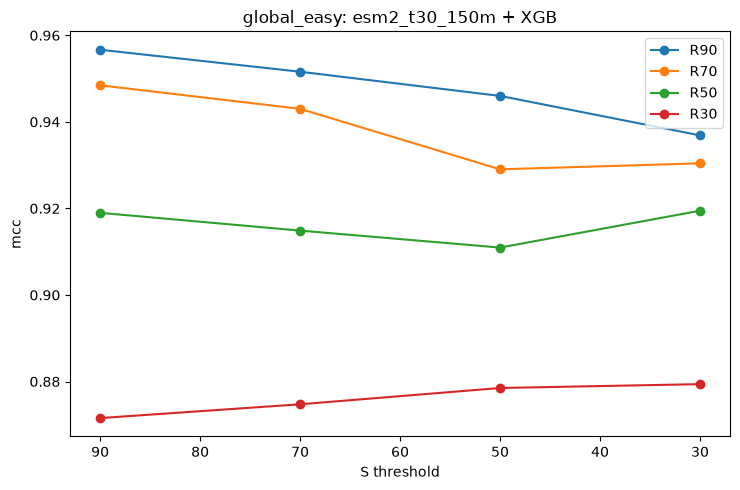

In [5]:
TASK = "global_easy"
REPRESENTATION = (
    "esm2_t30_150m"
    if "esm2_t30_150m" in master["representation"].unique()
    else sorted(master["representation"].unique())[0]
)
ALGORITHM = (
    "XGB"
    if "XGB" in master["algorithm"].unique()
    else sorted(master["algorithm"].unique())[0]
)
METRIC = "mcc"

g = master[
    master["task"].eq(TASK)
    & master["representation"].eq(REPRESENTATION)
    & master["algorithm"].eq(ALGORITHM)
].copy()

fig, ax = plt.subplots(figsize=(7.5, 5))
for r in R_LEVELS:
    curve = (
        g[g["R"].eq(r)]
        .set_index("S")
        .reindex(S_LEVELS)
    )
    ax.plot(
        S_LEVELS,
        curve[METRIC],
        marker="o",
        label=f"R{r}",
    )

ax.set_xlabel("S threshold")
ax.set_ylabel(METRIC)
ax.set_title(f"{TASK}: {REPRESENTATION} + {ALGORITHM}")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 4. Standardize the Stage12B S-delta schema

In [6]:
display(s_deltas.head())
print("Columns:", list(s_deltas.columns))

# Accept either S_from/S_to or generic threshold_from/threshold_to naming.
if {"S_from", "S_to"} <= set(s_deltas.columns):
    S_FROM, S_TO = "S_from", "S_to"
elif {"threshold_from", "threshold_to"} <= set(s_deltas.columns):
    S_FROM, S_TO = "threshold_from", "threshold_to"
else:
    raise KeyError(
        "Could not identify S contrast columns. Expected S_from/S_to or threshold_from/threshold_to."
    )

R_FIXED = "R_fixed" if "R_fixed" in s_deltas.columns else "R"

metric_col = "metric"
delta_col = "delta"

s_metrics = sorted(s_deltas[metric_col].dropna().unique())
S_METRIC = "mcc" if "mcc" in s_metrics else s_metrics[0]

sd = s_deltas[s_deltas[metric_col].eq(S_METRIC)].copy()

print("Primary S metric:", S_METRIC)
print("Rows:", len(sd))

,task,representation,algorithm,metric,R_fixed,S_from,S_to,threshold_step,value_from,value_to,delta,absolute_threshold_change,native_test_note
0,global_easy,esm2_t30_150m,KNN,mcc,90,90,70,S90->S70,0.962580,0.954598,-0.007982,20,Native-test split-stringency contrast at fixed...
1,global_easy,esm2_t30_150m,KNN,mcc,90,90,50,S90->S50,0.962580,0.953930,-0.008650,40,Native-test split-stringency contrast at fixed...
2,global_easy,esm2_t30_150m,KNN,mcc,90,90,30,S90->S30,0.962580,0.948037,-0.014544,60,Native-test split-stringency contrast at fixed...
3,global_easy,esm2_t30_150m,KNN,mcc,90,70,50,S70->S50,0.954598,0.953930,-0.000668,20,Native-test split-stringency contrast at fixed...
4,global_easy,esm2_t30_150m,KNN,mcc,90,70,30,S70->S30,0.954598,0.948037,-0.006562,40,Native-test split-stringency contrast at fixed...


Columns: ['task', 'representation', 'algorithm', 'metric', 'R_fixed', 'S_from', 'S_to', 'threshold_step', 'value_from', 'value_to', 'delta', 'absolute_threshold_change', 'native_test_note']
Primary S metric: mcc
Rows: 3360


## 5. All six S contrasts at fixed R

,S_from,S_to,n,mean_delta,median_delta,std_delta,q25,q75,min_delta,max_delta,fraction_negative,fraction_positive,contrast
0,50,30,560,-0.016838,-0.008059,0.065725,-0.031369,0.008180,-0.583909,0.179482,0.633929,0.335714,S50→S30
1,70,30,560,-0.032198,-0.012054,0.081603,-0.049271,0.003937,-0.542455,0.254277,0.662500,0.305357,S70→S30
2,70,50,560,-0.015360,-0.005392,0.051468,-0.030997,0.007078,-0.616528,0.217952,0.591071,0.380357,S70→S50
3,90,30,560,-0.038694,-0.016742,0.093595,-0.046596,0.000495,-0.693917,0.254274,0.708929,0.264286,S90→S30
4,90,50,560,-0.021856,-0.008803,0.062124,-0.035591,0.004582,-0.616528,0.332676,0.651786,0.323214,S90→S50
5,90,70,560,-0.006496,-0.001793,0.039631,-0.016374,0.008816,-0.339206,0.235208,0.535714,0.403571,S90→S70


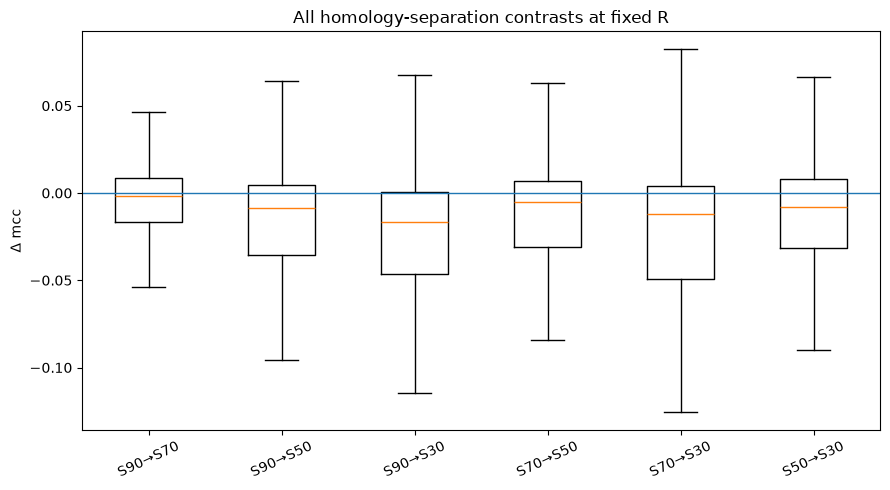

In [7]:
ordered_pairs = [
    (90, 70), (90, 50), (90, 30),
    (70, 50), (70, 30),
    (50, 30),
]

contrast_summary = (
    sd.groupby([S_FROM, S_TO], as_index=False)
    .agg(
        n=(delta_col, "size"),
        mean_delta=(delta_col, "mean"),
        median_delta=(delta_col, "median"),
        std_delta=(delta_col, "std"),
        q25=(delta_col, lambda x: x.quantile(0.25)),
        q75=(delta_col, lambda x: x.quantile(0.75)),
        min_delta=(delta_col, "min"),
        max_delta=(delta_col, "max"),
        fraction_negative=(delta_col, lambda x: (x < 0).mean()),
        fraction_positive=(delta_col, lambda x: (x > 0).mean()),
    )
)

contrast_summary["contrast"] = (
    "S" + contrast_summary[S_FROM].astype(str)
    + "→S" + contrast_summary[S_TO].astype(str)
)

display(contrast_summary)

fig, ax = plt.subplots(figsize=(9, 5))
data = [
    sd.loc[
        sd[S_FROM].eq(a) & sd[S_TO].eq(b),
        delta_col,
    ].dropna().to_numpy()
    for a, b in ordered_pairs
]
labels = [f"S{a}→S{b}" for a, b in ordered_pairs]

ax.boxplot(data, tick_labels=labels, showfliers=False)
ax.axhline(0, linewidth=1)
ax.set_ylabel(f"Δ {S_METRIC}")
ax.set_title("All homology-separation contrasts at fixed R")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

## 6. Stepwise S effects and dominant separation transition

In [8]:
step_pairs = [(90, 70), (70, 50), (50, 30)]

step_sd = sd[
    sd.apply(
        lambda x: (int(x[S_FROM]), int(x[S_TO])) in step_pairs,
        axis=1,
    )
].copy()

step_sd["abs_delta"] = step_sd[delta_col].abs()
step_sd["step"] = (
    "S" + step_sd[S_FROM].astype(str)
    + "→S" + step_sd[S_TO].astype(str)
)

step_summary = (
    step_sd.groupby([S_FROM, S_TO], as_index=False)
    .agg(
        mean_delta=(delta_col, "mean"),
        median_delta=(delta_col, "median"),
        mean_abs_delta=(delta_col, lambda x: x.abs().mean()),
        median_abs_delta=(delta_col, lambda x: x.abs().median()),
        fraction_negative=(delta_col, lambda x: (x < 0).mean()),
    )
)

step_summary["step"] = (
    "S" + step_summary[S_FROM].astype(str)
    + "→S" + step_summary[S_TO].astype(str)
)

display(step_summary)

dominant_step = (
    step_sd.sort_values(
        ["task", "representation", "algorithm", R_FIXED, "abs_delta"],
        ascending=[True, True, True, True, False],
        kind="stable",
    )
    .groupby(
        ["task", "representation", "algorithm", R_FIXED],
        as_index=False,
    )
    .first()
)

display(
    dominant_step["step"]
    .value_counts(normalize=True)
    .rename("fraction_of_model×R_groups")
    .to_frame()
)

,S_from,S_to,mean_delta,median_delta,mean_abs_delta,median_abs_delta,fraction_negative,step
0,50,30,-0.016838,-0.008059,0.035937,0.020756,0.633929,S50→S30
1,70,50,-0.015360,-0.005392,0.030048,0.016938,0.591071,S70→S50
2,90,70,-0.006496,-0.001793,0.023088,0.012320,0.535714,S90→S70


,fraction_of_model×R_groups
step,
S50→S30,0.405357
S70→S50,0.337500
S90→S70,0.257143


In [9]:
dominant_by_task = (
    dominant_step.groupby(["task", "step"])
    .size()
    .rename("n")
    .reset_index()
)

dominant_by_task["fraction_within_task"] = (
    dominant_by_task["n"]
    / dominant_by_task.groupby("task")["n"].transform("sum")
)

display(
    dominant_by_task.sort_values(
        ["task", "fraction_within_task"],
        ascending=[True, False],
    )
)

,task,step,n,fraction_within_task
0,global_easy,S50→S30,34,0.4250
1,global_easy,S70→S50,33,0.4125
2,global_easy,S90→S70,13,0.1625
4,global_hard,S70→S50,28,0.3500
3,global_hard,S50→S30,27,0.3375
5,global_hard,S90→S70,25,0.3125
6,global_mixed,S50→S30,32,0.4000
7,global_mixed,S70→S50,29,0.3625
8,global_mixed,S90→S70,19,0.2375
9,multiclass_clean,S50→S30,39,0.4875


## 7. Response-shape classification

For each `task × representation × algorithm × R`, classify the `S90→S70→S50→S30` trajectory.

A tolerance of 0.005 MCC prevents tiny fluctuations from being overinterpreted.

In [10]:
MONOTONIC_TOL = 0.005

shape_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys

    curve = (
        grp.set_index("S")
        .reindex(S_LEVELS)["mcc"]
        .astype(float)
    )

    if curve.isna().any():
        continue

    values = curve.to_numpy()
    diffs = np.diff(values)

    if np.all(np.abs(diffs) <= MONOTONIC_TOL):
        shape = "flat"
    elif np.all(diffs <= MONOTONIC_TOL):
        shape = "monotonic_decrease"
    elif np.all(diffs >= -MONOTONIC_TOL):
        shape = "monotonic_increase"
    else:
        shape = "nonmonotonic"

    shape_rows.append(
        {
            "task": task,
            "representation": rep,
            "algorithm": alg,
            "R": r,
            "shape": shape,
            "S90": values[0],
            "S70": values[1],
            "S50": values[2],
            "S30": values[3],
            "delta_S30_minus_S90": values[3] - values[0],
            "max_step_abs": float(np.max(np.abs(diffs))),
        }
    )

shape_df = pd.DataFrame(shape_rows)

display(
    shape_df["shape"]
    .value_counts(normalize=True)
    .rename("fraction")
    .to_frame()
)

display(
    pd.crosstab(
        shape_df["task"],
        shape_df["shape"],
        normalize="index",
    )
)

,fraction
shape,
nonmonotonic,0.633929
monotonic_decrease,0.266071
monotonic_increase,0.055357
flat,0.044643


shape,flat,monotonic_decrease,monotonic_increase,nonmonotonic
task,,,,
global_easy,0.0625,0.3750,0.0500,0.5125
global_hard,0.0375,0.2125,0.0250,0.7250
global_mixed,0.0125,0.3625,0.0125,0.6125
multiclass_clean,0.0000,0.1750,0.0500,0.7750
subtype_depolymerase,0.0250,0.1250,0.1000,0.7500
subtype_endolysin,0.0000,0.3500,0.0875,0.5625
subtype_val,0.1750,0.2625,0.0625,0.5000


## 8. Performance retention relative to S90

,mean,median,std,min,max
S,,,,,
30,-0.038694,-0.016742,0.093595,-0.693917,0.254274
50,-0.021856,-0.008803,0.062124,-0.616528,0.332676
70,-0.006496,-0.001793,0.039631,-0.339206,0.235208
90,0.000000,0.000000,0.000000,0.000000,0.000000


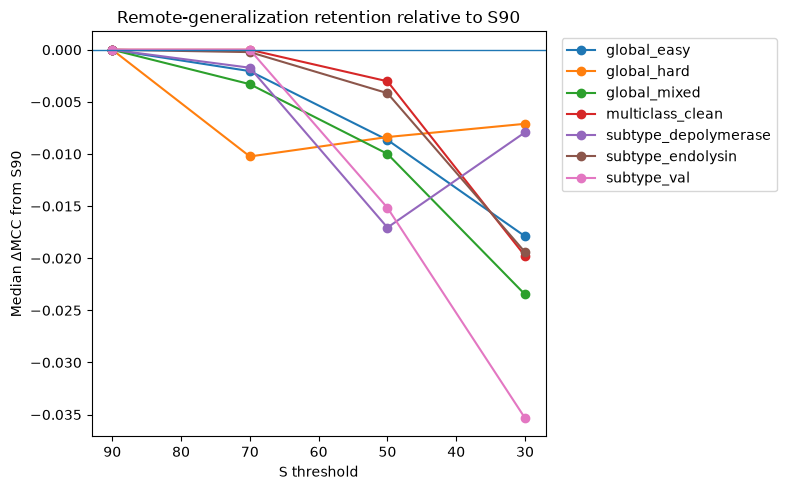

In [11]:
retention_rows = []

for keys, grp in master.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys
    lookup = dict(zip(grp["S"].astype(int), grp["mcc"].astype(float)))

    if 90 not in lookup:
        continue

    baseline = lookup[90]

    for s in S_LEVELS:
        if s not in lookup:
            continue

        retention_rows.append(
            {
                "task": task,
                "representation": rep,
                "algorithm": alg,
                "R": r,
                "S": s,
                "mcc": lookup[s],
                "delta_from_S90": lookup[s] - baseline,
                "mcc_ratio_to_S90": (
                    lookup[s] / baseline
                    if baseline != 0
                    else np.nan
                ),
            }
        )

performance_retention = pd.DataFrame(retention_rows)

display(
    performance_retention.groupby("S")["delta_from_S90"]
    .agg(["mean", "median", "std", "min", "max"])
)

fig, ax = plt.subplots(figsize=(8, 5))
for task, g in performance_retention.groupby("task"):
    summary = (
        g.groupby("S")["delta_from_S90"]
        .median()
        .reindex(S_LEVELS)
    )
    ax.plot(
        S_LEVELS,
        summary,
        marker="o",
        label=task,
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("S threshold")
ax.set_ylabel("Median ΔMCC from S90")
ax.set_title("Remote-generalization retention relative to S90")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 9. Task-specific homology sensitivity

In [12]:
extreme_s = sd[
    sd[S_FROM].eq(90)
    & sd[S_TO].eq(30)
].copy()

def sensitivity_table(df, group):
    return (
        df.groupby(group, as_index=False)
        .agg(
            mean_delta=(delta_col, "mean"),
            median_delta=(delta_col, "median"),
            mean_abs_delta=(delta_col, lambda x: x.abs().mean()),
            median_abs_delta=(delta_col, lambda x: x.abs().median()),
            min_delta=(delta_col, "min"),
            max_delta=(delta_col, "max"),
            fraction_negative=(delta_col, lambda x: (x < 0).mean()),
        )
        .sort_values("median_abs_delta", ascending=False)
    )

task_sensitivity = sensitivity_table(extreme_s, "task")
display(task_sensitivity)

,task,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
6,subtype_val,-0.122407,-0.035334,0.153979,0.077636,-0.693917,0.254274,0.5500
5,subtype_endolysin,-0.031038,-0.019415,0.043830,0.027656,-0.309527,0.065058,0.7000
3,multiclass_clean,-0.025357,-0.019777,0.033628,0.025002,-0.120168,0.060397,0.8000
2,global_mixed,-0.036990,-0.023472,0.039109,0.023472,-0.250811,0.019251,0.8500
4,subtype_depolymerase,-0.012164,-0.007922,0.032444,0.021504,-0.119394,0.128736,0.6125
0,global_easy,-0.033751,-0.017895,0.038358,0.018622,-0.291342,0.026300,0.7750
1,global_hard,-0.009150,-0.007104,0.018445,0.012490,-0.113485,0.039707,0.6750


## 10. Representation-specific homology sensitivity

,representation,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
2,onehot_1024,-0.066185,-0.033905,0.074723,0.037725,-0.492527,0.128736,0.721429
3,roxy_48,-0.033859,-0.020911,0.052688,0.035806,-0.561890,0.157062,0.692857
1,esm2_t6_8m,-0.036658,-0.017782,0.050457,0.020476,-0.693917,0.254274,0.685714
0,esm2_t30_150m,-0.018073,-0.011272,0.027729,0.015238,-0.355573,0.131319,0.735714


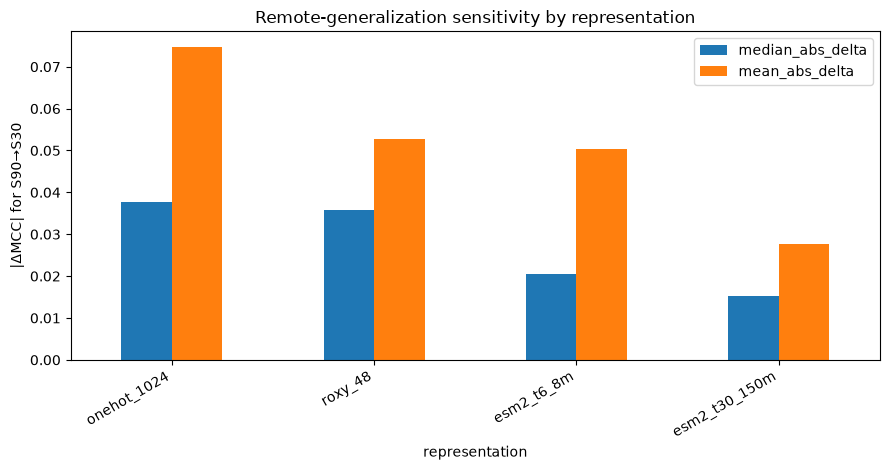

In [13]:
rep_sensitivity = sensitivity_table(extreme_s, "representation")
display(rep_sensitivity)

rep_sensitivity.set_index("representation")[
    ["median_abs_delta", "mean_abs_delta"]
].plot(kind="bar", figsize=(9, 4.8))

plt.ylabel("|ΔMCC| for S90→S30")
plt.title("Remote-generalization sensitivity by representation")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

## 11. Representation-specific degradation curves

The important question is not only whether a representation has higher MCC, but whether its performance **degrades more slowly** as train–test homology becomes more restrictive.

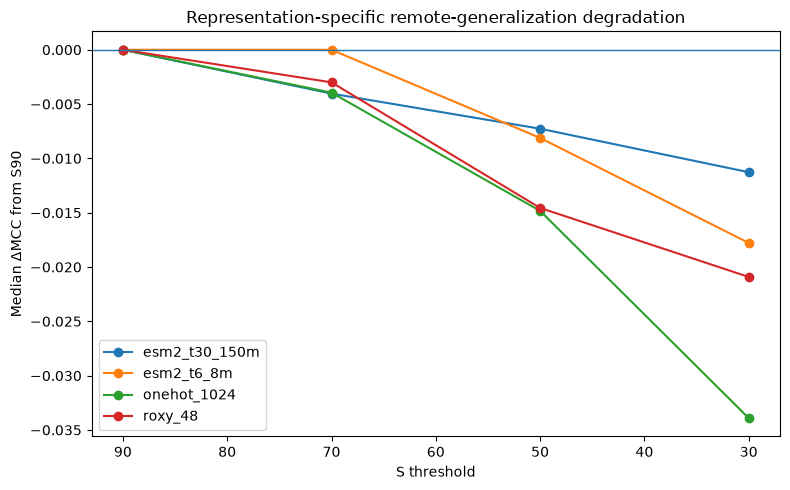

In [14]:
rep_curve = (
    performance_retention.groupby(["representation", "S"])[
        "delta_from_S90"
    ]
    .median()
    .reset_index()
)

fig, ax = plt.subplots(figsize=(8, 5))

for rep, g in rep_curve.groupby("representation"):
    g = g.set_index("S").reindex(S_LEVELS)
    ax.plot(
        S_LEVELS,
        g["delta_from_S90"],
        marker="o",
        label=rep,
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("S threshold")
ax.set_ylabel("Median ΔMCC from S90")
ax.set_title("Representation-specific remote-generalization degradation")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 12. Learner-specific homology sensitivity

In [15]:
alg_sensitivity = sensitivity_table(extreme_s, "algorithm")
display(alg_sensitivity)

,algorithm,mean_delta,median_delta,mean_abs_delta,median_abs_delta,min_delta,max_delta,fraction_negative
0,KNN,-0.057052,-0.023941,0.069295,0.031840,-0.693917,0.128736,0.723214
4,XGB,-0.035048,-0.017731,0.051532,0.023451,-0.500045,0.186074,0.714286
2,MLP,-0.031611,-0.016422,0.045632,0.022279,-0.515540,0.254274,0.732143
3,RF,-0.045615,-0.018467,0.052071,0.022205,-0.411735,0.039421,0.732143
1,LR,-0.024145,-0.009153,0.038465,0.017958,-0.488751,0.100984,0.642857


# 13. Reconstruct S-dependent split topology

At fixed `task × R`, the underlying R-level biological universe is constant. Changing S changes:

- the cluster granularity used to enforce separation;
- the number of train/test clusters;
- the number of entities per cluster;
- which clusters enter test;
- potentially test prevalence/support.

This section reconstructs those descriptors from the frozen predictive-universe files.

In [16]:
TOPOLOGY_CACHE = CACHE_DIR / "rq3_split_topology.tsv"
FORCE_RECOUNT = False

def infer_split_column(df):
    for c in ["split", "outer_split", "partition", "set"]:
        if c in df.columns:
            return c
    raise KeyError(f"No split column found. Columns: {list(df.columns)}")

def infer_cluster_column(df):
    for c in ["cluster_id", "mmseqs_cluster_id", "cluster"]:
        if c in df.columns:
            return c
    raise KeyError(f"No cluster column found. Columns: {list(df.columns)}")

def infer_binary_label_column(df):
    candidates = [
        "y", "y_true", "label", "target",
        "binary_label", "class_label",
    ]
    allowed = {
        "0", "1", "0.0", "1.0",
        "positive", "negative", "p", "n",
    }

    for c in candidates:
        if c not in df.columns:
            continue

        vals = set(
            pd.Series(df[c])
            .dropna()
            .astype(str)
            .str.lower()
            .unique()
        )

        if vals and vals <= allowed:
            return c

    return None

def build_topology():
    rows = []

    for task, task_path in TASK_PATHS.items():
        for r in R_LEVELS:
            for s in S_LEVELS:
                path = (
                    PREDICTIVE_ROOT
                    / task_path
                    / f"R{r}_S{s}"
                    / "eligible_entities.tsv.gz"
                )

                if not path.is_file():
                    rows.append(
                        {
                            "task": task,
                            "R": r,
                            "S": s,
                            "found": False,
                            "path": str(path),
                        }
                    )
                    continue

                df = pd.read_csv(path, sep="\t", low_memory=False)

                split_col = infer_split_column(df)
                cluster_col = infer_cluster_column(df)

                split_norm = df[split_col].astype(str).str.lower()
                train = split_norm.eq("train")
                test = split_norm.eq("test")

                n_train = int(train.sum())
                n_test = int(test.sum())

                n_clusters_total = int(df[cluster_col].nunique())
                n_clusters_train = int(df.loc[train, cluster_col].nunique())
                n_clusters_test = int(df.loc[test, cluster_col].nunique())

                row = {
                    "task": task,
                    "R": r,
                    "S": s,
                    "found": True,
                    "n_total": len(df),
                    "n_train": n_train,
                    "n_test": n_test,
                    "test_fraction": (
                        n_test / len(df)
                        if len(df)
                        else np.nan
                    ),
                    "n_clusters_total": n_clusters_total,
                    "n_clusters_train": n_clusters_train,
                    "n_clusters_test": n_clusters_test,
                    "entities_per_cluster_total": (
                        len(df) / n_clusters_total
                        if n_clusters_total > 0
                        else np.nan
                    ),
                    "entities_per_train_cluster": (
                        n_train / n_clusters_train
                        if n_clusters_train > 0
                        else np.nan
                    ),
                    "entities_per_test_cluster": (
                        n_test / n_clusters_test
                        if n_clusters_test > 0
                        else np.nan
                    ),
                }

                if task in BINARY_TASKS:
                    label_col = infer_binary_label_column(df)

                    if label_col:
                        y = df[label_col].astype(str).str.lower()
                        pos = y.isin({"1", "1.0", "positive", "p"})

                        row["n_positive_train"] = int((pos & train).sum())
                        row["n_positive_test"] = int((pos & test).sum())
                        row["test_prevalence_from_universe"] = (
                            int((pos & test).sum()) / n_test
                            if n_test > 0
                            else np.nan
                        )

                rows.append(row)

    return pd.DataFrame(rows)

if TOPOLOGY_CACHE.is_file() and not FORCE_RECOUNT:
    topology = pd.read_csv(
        TOPOLOGY_CACHE,
        sep="\t",
        low_memory=False,
    )
    print("Loaded:", TOPOLOGY_CACHE)
else:
    topology = build_topology()
    topology.to_csv(
        TOPOLOGY_CACHE,
        sep="\t",
        index=False,
    )
    print("Wrote:", TOPOLOGY_CACHE)

print("Cells found:", topology["found"].sum(), "/", len(topology))
display(topology.head())

Wrote: /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq3_split_topology.tsv
Cells found: 112 / 112


,task,R,S,found,n_total,n_train,n_test,test_fraction,n_clusters_total,n_clusters_train,n_clusters_test,entities_per_cluster_total,entities_per_train_cluster,entities_per_test_cluster,n_positive_train,n_positive_test,test_prevalence_from_universe
0,global_easy,90,90,True,30092,21049,9043,0.300512,30083,21041,9042,1.000299,1.000380,1.000111,3324.0,1439.0,0.159129
1,global_easy,90,70,True,30092,21050,9042,0.300479,21485,15029,6456,1.400605,1.400625,1.400558,3321.0,1442.0,0.159478
2,global_easy,90,50,True,30092,21068,9024,0.299880,14786,10284,4502,2.035168,2.048619,2.004442,3380.0,1383.0,0.153258
3,global_easy,90,30,True,30092,21076,9016,0.299615,8995,6238,2757,3.345414,3.378647,3.270221,3284.0,1479.0,0.164042
4,global_easy,70,90,True,21512,15058,6454,0.300019,21507,15055,6452,1.000232,1.000199,1.000310,2437.0,1026.0,0.158971


## 14. Split-size stability across S

In [17]:
display(
    topology[topology["found"]]
    .groupby("S")[
        ["n_train", "n_test", "test_fraction"]
    ]
    .agg(["mean", "median", "min", "max"])
)

n_train                            n_test                    test_fraction                              
            mean  median   min    max         mean  median  min   max          mean    median       min       max
S                                                                                                                
30  10061.500000  9599.5  1099  22434  4300.071429  4086.5  472  9549      0.299204  0.299622  0.292149  0.303496
50  10052.892857  9582.0  1099  22360  4308.678571  4104.0  472  9623      0.299948  0.299978  0.296793  0.303874
70  10052.321429  9579.0  1096  22382  4309.250000  4107.0  475  9601      0.299966  0.300188  0.296263  0.302675
90  10051.928571  9582.0  1096  22385  4309.642857  4104.0  475  9598      0.299968  0.299985  0.296793  0.302355

If test fractions remain close to the intended ~0.30 across S, then systematic performance differences are unlikely to be explained simply by gross train/test size changes.

## 15. S changes cluster granularity

In [18]:
granularity = (
    topology[topology["found"]]
    .groupby("S")[
        [
            "n_clusters_total",
            "n_clusters_train",
            "n_clusters_test",
            "entities_per_cluster_total",
            "entities_per_train_cluster",
            "entities_per_test_cluster",
        ]
    ]
    .agg(["mean", "median", "min", "max"])
)

display(granularity)

n_clusters_total                       n_clusters_train                      n_clusters_test                    entities_per_cluster_total                               entities_per_train_cluster            \
               mean   median   min    max             mean  median   min    max            mean  median  min   max                       mean    median       min       max                       mean    median   
S                                                                                                                                                                                                                  
30      7007.964286   8548.5  1557   9829      4893.178571  5968.5  1077   6892     2114.785714  2569.5  466  2997                   2.000481  1.818077  1.002233  3.345414                   2.009628  1.826075   
50     10233.357143  13522.5  1562  15875      7152.428571  9447.0  1092  11117     3080.928571  4066.5  470  4778                   1.357525  1.198134  1.000780  2.035168                   1.359713  1.198114   
70     12736.857143  13680.0  1568  22897      8917.607143  9574.0  1093  16016     3819.250000  4106.0  475  6881                   1.098450  1.001726  1.000362  1.400605                   1.098329  1.001800   
90     14351.857143  13683.5  1568  31955     10045.000000  9580.0  1093  22368     4306.857143  4103.5  475  9587                   1.001117  1.000841  1.000121  1.003630                   1.001171  1.000759   

                       entities_per_test_cluster                                
         min       max                      mean    median       min       max  
S                                                                               
30  1.001752  3.378647                  1.979562  1.799754  1.001953  3.270221  
50  1.000477  2.050793                  1.352528  1.198179  1.000805  2.014023  
70  1.000159  1.400625                  1.098745  1.001729  1.000000  1.415961  
90  1.000000  1.003893                  1.000993  1.000616  1.000000  1.004127

,median_clusters_total,median_entities_per_cluster,median_test_fraction
S,,,
90,13683.5,1.000841,0.299985
70,13680.0,1.001726,0.300188
50,13522.5,1.198134,0.299978
30,8548.5,1.818077,0.299622


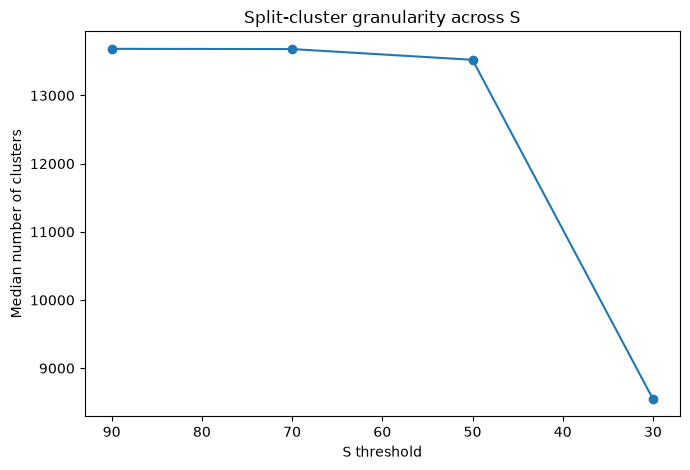

In [19]:
granularity_summary = (
    topology[topology["found"]]
    .groupby("S", as_index=False)
    .agg(
        median_clusters_total=("n_clusters_total", "median"),
        median_entities_per_cluster=(
            "entities_per_cluster_total",
            "median",
        ),
        median_test_fraction=("test_fraction", "median"),
    )
    .set_index("S")
    .reindex(S_LEVELS)
)

display(granularity_summary)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.plot(
    S_LEVELS,
    granularity_summary["median_clusters_total"],
    marker="o",
)
ax.set_xlabel("S threshold")
ax.set_ylabel("Median number of clusters")
ax.set_title("Split-cluster granularity across S")
ax.invert_xaxis()
plt.tight_layout()
plt.show()

### Interpretation guardrail

A lower S generally produces coarser/larger homology groups. Because clustering is recomputed independently at each threshold, changes in cluster count describe **partition granularity**, not nested cluster survival.

## 16. Test prevalence and support drift across S

In [20]:
prevalence_cols = [
    c for c in [
        "task", "R", "S",
        "prevalence_for_ap",
        "n_test",
        "n_positive",
        "support_positive",
    ]
    if c in master.columns
]

native_prev = (
    master[prevalence_cols]
    .drop_duplicates(
        subset=["task", "R", "S"]
    )
)

if "prevalence_for_ap" in native_prev.columns:
    display(
        native_prev[
            native_prev["task"].isin(BINARY_TASKS)
        ]
        .groupby(["task", "S"])["prevalence_for_ap"]
        .agg(["mean", "median", "min", "max"])
    )
else:
    print("No prevalence column available in supervised master.")

mean    median       min       max
task                 S                                         
global_easy          30  0.169536  0.165976  0.161973  0.184220
                     50  0.164558  0.161816  0.153258  0.181343
                     70  0.165801  0.161242  0.159478  0.181241
                     90  0.166190  0.160740  0.158971  0.184308
global_hard          30  0.694543  0.695647  0.653479  0.733400
                     50  0.688572  0.688894  0.655267  0.721233
                     70  0.693273  0.701731  0.657104  0.712526
                     90  0.695212  0.701647  0.656635  0.720919
global_mixed         30  0.148064  0.149411  0.130149  0.163286
                     50  0.150062  0.148889  0.137386  0.165085
                     70  0.152995  0.150947  0.146009  0.164078
                     90  0.152733  0.150565  0.146476  0.163328
subtype_depolymerase 30  0.025247  0.024270  0.017362  0.035088
                     50  0.024132  0.023170  0.016364  0.033826
                     70  0.023620  0.022686  0.015192  0.033918
                     90  0.023806  0.022633  0.015879  0.034078
subtype_endolysin    30  0.128913  0.127586  0.116487  0.143993
                     50  0.125394  0.126309  0.121276  0.127682
                     70  0.123810  0.123213  0.120726  0.128088
                     90  0.126056  0.126958  0.120945  0.129362
subtype_val          30  0.004610  0.004947  0.001707  0.006841
                     50  0.004521  0.004343  0.002561  0.006836
                     70  0.004392  0.004010  0.002684  0.006863
                     90  0.004506  0.004004  0.003174  0.006844

## 17. Is apparent S degradation associated with prevalence drift?

This is descriptive only. It checks whether large native-test MCC changes systematically occur alongside large changes in test prevalence.

In [21]:
# Build prevalence contrasts directly from the master table.
prev_map = (
    master[
        master["task"].isin(BINARY_TASKS)
    ][
        [
            "task", "representation", "algorithm",
            "R", "S", "prevalence_for_ap",
        ]
    ]
    .copy()
)

prev_contrast_rows = []

for keys, grp in prev_map.groupby(
    ["task", "representation", "algorithm", "R"]
):
    task, rep, alg, r = keys

    lookup = dict(
        zip(
            grp["S"].astype(int),
            grp["prevalence_for_ap"].astype(float),
        )
    )

    for s_from, s_to in ordered_pairs:
        if s_from in lookup and s_to in lookup:
            prev_contrast_rows.append(
                {
                    "task": task,
                    "representation": rep,
                    "algorithm": alg,
                    "R_fixed": r,
                    "S_from": s_from,
                    "S_to": s_to,
                    "delta_prevalence": (
                        lookup[s_to] - lookup[s_from]
                    ),
                }
            )

prev_deltas = pd.DataFrame(prev_contrast_rows)

# Collapse duplicated prevalence rows across representations/algorithms
# only after preserving the keys needed to join.
extreme_prev = prev_deltas[
    prev_deltas["S_from"].eq(90)
    & prev_deltas["S_to"].eq(30)
].copy()

join_keys = ["task", "representation", "algorithm"]
if R_FIXED == "R_fixed":
    extreme_s_for_join = extreme_s.rename(
        columns={R_FIXED: "R_fixed"}
    )
else:
    extreme_s_for_join = extreme_s.rename(
        columns={R_FIXED: "R_fixed"}
    )

if set(join_keys + ["R_fixed"]) <= set(extreme_s_for_join.columns):
    prev_perf = extreme_s_for_join.merge(
        extreme_prev,
        on=join_keys + ["R_fixed"],
        how="left",
    )

    x = prev_perf[
        [delta_col, "delta_prevalence"]
    ].dropna()

    print(
        "Spearman Δprevalence vs ΔMCC:",
        x["delta_prevalence"].corr(
            x[delta_col],
            method="spearman",
        )
        if len(x) > 3
        else np.nan,
    )

Spearman Δprevalence vs ΔMCC: -0.03082591856361051


## 18. Binary AP-skill remote-generalization sensitivity

In [22]:
if "ap_skill" in master.columns:
    binary = master[
        master["task"].isin(BINARY_TASKS)
    ].copy()

    ap_rows = []

    for keys, grp in binary.groupby(
        ["task", "representation", "algorithm", "R"]
    ):
        task, rep, alg, r = keys

        lookup = dict(
            zip(
                grp["S"].astype(int),
                grp["ap_skill"].astype(float),
            )
        )

        for s_from, s_to in ordered_pairs:
            if s_from in lookup and s_to in lookup:
                ap_rows.append(
                    {
                        "task": task,
                        "representation": rep,
                        "algorithm": alg,
                        "R_fixed": r,
                        "S_from": s_from,
                        "S_to": s_to,
                        "delta_ap_skill": (
                            lookup[s_to] - lookup[s_from]
                        ),
                    }
                )

    ap_s_deltas = pd.DataFrame(ap_rows)

    display(
        ap_s_deltas[
            ap_s_deltas["S_from"].eq(90)
            & ap_s_deltas["S_to"].eq(30)
        ]
        .groupby("task")["delta_ap_skill"]
        .agg(["mean", "median", "std", "min", "max"])
    )

,mean,median,std,min,max
task,,,,,
global_easy,-0.027300,-0.006415,0.061575,-0.263142,0.052717
global_hard,-0.004606,-0.003365,0.012813,-0.075198,0.033281
global_mixed,-0.042391,-0.030251,0.054547,-0.292383,0.055839
subtype_depolymerase,-0.010056,-0.012096,0.051828,-0.197368,0.107375
subtype_endolysin,-0.032797,-0.022874,0.059622,-0.236935,0.090617
subtype_val,-0.119847,-0.051919,0.223838,-0.670502,0.296599


## 19. Representation advantage under increasingly remote generalization

A key *Briefings* question is whether pretrained representations become **more valuable as S becomes stricter**.

For each task × algorithm × R, compare the representation gap at each S.

This section focuses on T30 versus simpler representations.

In [23]:
REP_ORDER = [
    r for r in [
        "roxy_48",
        "onehot_1024",
        "esm2_t6_8m",
        "esm2_t30_150m",
    ]
    if r in master["representation"].unique()
]

rep_gap_rows = []

for keys, grp in master.groupby(
    ["task", "algorithm", "R", "S"]
):
    task, alg, r, s = keys

    lookup = dict(
        zip(
            grp["representation"],
            grp["mcc"].astype(float),
        )
    )

    if "esm2_t30_150m" not in lookup:
        continue

    for comparator in [
        "roxy_48",
        "onehot_1024",
        "esm2_t6_8m",
    ]:
        if comparator not in lookup:
            continue

        rep_gap_rows.append(
            {
                "task": task,
                "algorithm": alg,
                "R": r,
                "S": s,
                "comparison": f"T30_minus_{comparator}",
                "delta_mcc": (
                    lookup["esm2_t30_150m"]
                    - lookup[comparator]
                ),
            }
        )

rep_gaps = pd.DataFrame(rep_gap_rows)

display(
    rep_gaps.groupby(["comparison", "S"])["delta_mcc"]
    .agg(["mean", "median", "std", "min", "max"])
)

mean    median       std       min       max
comparison            S                                                   
T30_minus_esm2_t6_8m  30  0.098041  0.090853  0.104014 -0.086975  0.533816
                      50  0.082158  0.078380  0.070840 -0.013479  0.470590
                      70  0.078637  0.075297  0.071231 -0.014585  0.470589
                      90  0.079456  0.069400  0.073170 -0.023111  0.470591
T30_minus_onehot_1024 30  0.447081  0.459674  0.225540  0.088016  0.912530
                      50  0.421340  0.415973  0.215600  0.096456  0.908907
                      70  0.410220  0.407170  0.215903  0.089376  0.909023
                      90  0.398969  0.368655  0.213130  0.080443  0.925583
T30_minus_roxy_48     30  0.242562  0.250246  0.155509  0.032216  0.742903
                      50  0.235648  0.239588  0.148015  0.025585  0.760774
                      70  0.227749  0.225875  0.143392  0.035063  0.752165
                      90  0.226776  0.213646  0.152442  0.033235  0.784253

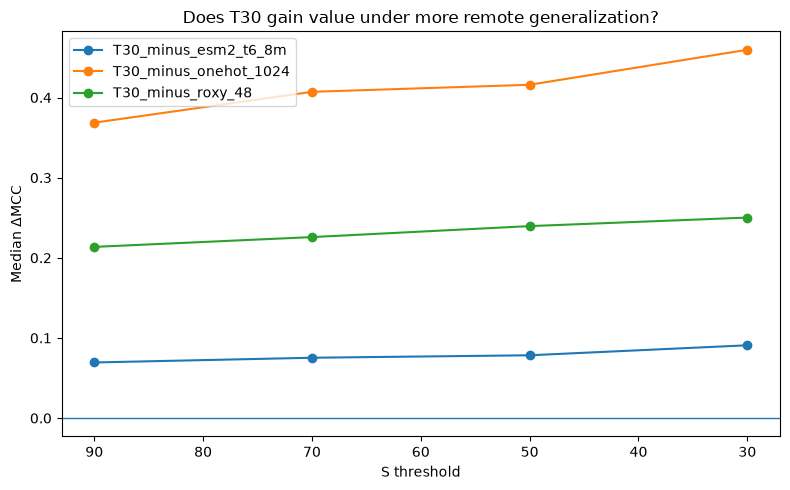

In [24]:
fig, ax = plt.subplots(figsize=(8, 5))

for comparison, g in rep_gaps.groupby("comparison"):
    summary = (
        g.groupby("S")["delta_mcc"]
        .median()
        .reindex(S_LEVELS)
    )

    ax.plot(
        S_LEVELS,
        summary,
        marker="o",
        label=comparison,
    )

ax.axhline(0, linewidth=1)
ax.set_xlabel("S threshold")
ax.set_ylabel("Median ΔMCC")
ax.set_title("Does T30 gain value under more remote generalization?")
ax.legend()
ax.invert_xaxis()
plt.tight_layout()
plt.show()

## 20. Homology sensitivity conditioned by R

This is the mirror image of the RQ2 conditioning analysis.

If the `S90→S30` effect changes strongly across R, that is evidence motivating the formal `R×S` interaction RQ.

In [25]:
extreme_by_r = (
    extreme_s.groupby(R_FIXED, as_index=False)
    .agg(
        mean_delta=(delta_col, "mean"),
        median_delta=(delta_col, "median"),
        mean_abs_delta=(delta_col, lambda x: x.abs().mean()),
        median_abs_delta=(delta_col, lambda x: x.abs().median()),
        fraction_negative=(delta_col, lambda x: (x < 0).mean()),
    )
)

display(extreme_by_r)

,R_fixed,mean_delta,median_delta,mean_abs_delta,median_abs_delta,fraction_negative
0,30,0.000551,4.334396e-07,0.019982,0.013646,0.450000
1,50,-0.003931,-5.682645e-03,0.028377,0.017602,0.592857
2,70,-0.055813,-3.105599e-02,0.059366,0.031056,0.842857
3,90,-0.095582,-4.713108e-02,0.097871,0.048235,0.950000


## 21. VAL low-support diagnostic under S

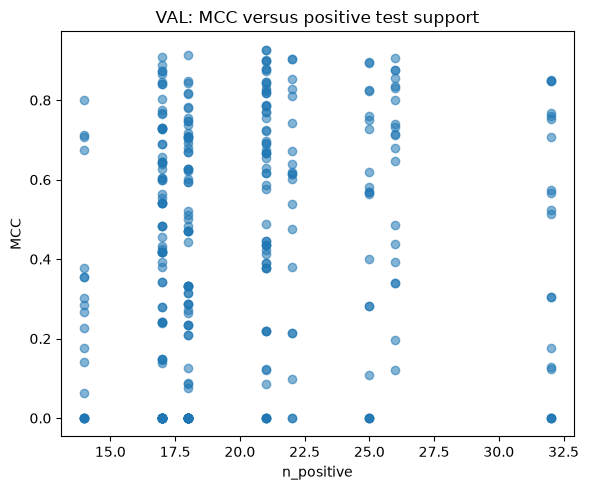

Spearman support vs MCC: 0.22592094554894349


In [26]:
val = master[
    master["task"].eq("subtype_val")
].copy()

support_candidates = [
    "n_positive",
    "support_positive",
    "n_positive_test",
]

support_col = next(
    (c for c in support_candidates if c in val.columns),
    None,
)

if support_col:
    fig, ax = plt.subplots(figsize=(6, 5))
    ax.scatter(
        val[support_col],
        val["mcc"],
        alpha=0.55,
    )
    ax.set_xlabel(support_col)
    ax.set_ylabel("MCC")
    ax.set_title("VAL: MCC versus positive test support")
    plt.tight_layout()
    plt.show()

    x = val[[support_col, "mcc"]].dropna()

    if len(x) > 2:
        print(
            "Spearman support vs MCC:",
            x.corr(method="spearman").iloc[0, 1],
        )
else:
    print(
        "No positive-support column found. "
        "Treat VAL as evidence-limited and defer detailed support analysis."
    )

# 22. RQ3 synthesis

After execution, RQ3 should answer:

1. Does stricter train–test homology separation generally reduce performance?
2. How large is the median `S90→S30` loss?
3. Is remote-generalization degradation monotonic?
4. Is there a universal homology threshold where performance collapses?
5. Which biological tasks are most sensitive to remote generalization?
6. Which representations retain the most performance?
7. Does T30 become more advantageous as S becomes stricter?
8. Which learners are most homology-sensitive?
9. Does S substantially change train/test size, or mainly cluster topology and membership?
10. How much does test prevalence drift across S?
11. Is prevalence drift associated with apparent performance change?
12. Does the S effect depend strongly on R?
13. Which patterns should be carried into the full `R×S` interaction analysis?

In [27]:
rq3_rows = []

x = extreme_s[delta_col].dropna()

rq3_rows.append(
    {
        "evidence": "overall_S90_to_S30",
        "group": "all",
        "median_delta_mcc": x.median(),
        "mean_delta_mcc": x.mean(),
        "median_abs_delta_mcc": x.abs().median(),
        "fraction_negative": (x < 0).mean(),
        "n": len(x),
    }
)

for rec in task_sensitivity.to_dict("records"):
    rq3_rows.append(
        {
            "evidence": "S90_to_S30_by_task",
            "group": rec["task"],
            "median_delta_mcc": rec["median_delta"],
            "mean_delta_mcc": rec["mean_delta"],
            "median_abs_delta_mcc": rec["median_abs_delta"],
            "fraction_negative": rec["fraction_negative"],
        }
    )

for rec in rep_sensitivity.to_dict("records"):
    rq3_rows.append(
        {
            "evidence": "S90_to_S30_by_representation",
            "group": rec["representation"],
            "median_delta_mcc": rec["median_delta"],
            "mean_delta_mcc": rec["mean_delta"],
            "median_abs_delta_mcc": rec["median_abs_delta"],
            "fraction_negative": rec["fraction_negative"],
        }
    )

for shape, fraction in shape_df["shape"].value_counts(normalize=True).items():
    rq3_rows.append(
        {
            "evidence": "response_shape",
            "group": shape,
            "fraction": fraction,
        }
    )

rq3_summary = pd.DataFrame(rq3_rows)
display(rq3_summary)

SUMMARY_PATH = CACHE_DIR / "rq3_evidence_summary.tsv"
TOPOLOGY_OUT = CACHE_DIR / "rq3_split_topology.tsv"
RETENTION_PATH = CACHE_DIR / "rq3_performance_retention.tsv"
SHAPE_PATH = CACHE_DIR / "rq3_response_shapes.tsv"
REP_GAP_PATH = CACHE_DIR / "rq3_representation_gaps_by_S.tsv"

rq3_summary.to_csv(SUMMARY_PATH, sep="\t", index=False)
topology.to_csv(TOPOLOGY_OUT, sep="\t", index=False)
performance_retention.to_csv(RETENTION_PATH, sep="\t", index=False)
shape_df.to_csv(SHAPE_PATH, sep="\t", index=False)
rep_gaps.to_csv(REP_GAP_PATH, sep="\t", index=False)

print("Saved:")
for p in [
    SUMMARY_PATH,
    TOPOLOGY_OUT,
    RETENTION_PATH,
    SHAPE_PATH,
    REP_GAP_PATH,
]:
    print(" ", p)

,evidence,group,median_delta_mcc,mean_delta_mcc,median_abs_delta_mcc,fraction_negative,n,fraction
0,overall_S90_to_S30,all,-0.016742,-0.038694,0.022797,0.708929,560.0,NaN
1,S90_to_S30_by_task,subtype_val,-0.035334,-0.122407,0.077636,0.550000,NaN,NaN
2,S90_to_S30_by_task,subtype_endolysin,-0.019415,-0.031038,0.027656,0.700000,NaN,NaN
3,S90_to_S30_by_task,multiclass_clean,-0.019777,-0.025357,0.025002,0.800000,NaN,NaN
4,S90_to_S30_by_task,global_mixed,-0.023472,-0.036990,0.023472,0.850000,NaN,NaN
5,S90_to_S30_by_task,subtype_depolymerase,-0.007922,-0.012164,0.021504,0.612500,NaN,NaN
6,S90_to_S30_by_task,global_easy,-0.017895,-0.033751,0.018622,0.775000,NaN,NaN
7,S90_to_S30_by_task,global_hard,-0.007104,-0.009150,0.012490,0.675000,NaN,NaN
8,S90_to_S30_by_representation,onehot_1024,-0.033905,-0.066185,0.037725,0.721429,NaN,NaN
9,S90_to_S30_by_representation,roxy_48,-0.020911,-0.033859,0.035806,0.692857,NaN,NaN


Saved:
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq3_evidence_summary.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq3_split_topology.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq3_performance_retention.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq3_response_shapes.tsv
  /home/david/Desktop/colabs/inta_project/phagelytic_core_project/phagelysclass/results/analysis_supervised/notebook_cache/rq3_representation_gaps_by_S.tsv


## What this notebook should not conclude

Do not describe lower S as merely producing a “harder split”. Lower S changes the **homology structure of the train–test partition** and therefore the generalization regime being measured.

Do not interpret cluster counts across S as nested cluster survival.

Do not treat native S comparisons as paired protein-level comparisons; test membership changes with the cluster partition.

Do not finalize `R×S` interaction claims here. RQ3 establishes the main effect and heterogeneity of homology separation; the interaction RQ determines whether R and S act additively or condition one another.